# Tugas 1 - Prediksi Customer Churn dengan Artificial Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Rakha Makarim | 5054251010 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Churn Modelling Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling

Dataset berisi data 10.000 nasabah bank, seperti skor kredit, negara, usia, saldo, dan status keaktifan. Tujuan utama dari tugas ini adalah membangun model Artificial Neural Network (ANN) menggunakan **PyTorch** untuk memprediksi apakah seorang nasabah akan berhenti menjadi nasabah (churn, kolom `Exited`) atau tidak.

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan oleh ANN.
3. Eksperimen Model
   - Bangun model baseline Logistic Regression dan beberapa konfigurasi ANN.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil seluruh model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Dari torch, import juga torch.nn dan TensorDataset, DataLoader dari torch.utils.data.
# Set random seed agar hasil eksperimen dapat direproduksi, gunakan torch.manual_seed(42) dan np.random.seed(42).

import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score, confusion_matrix)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)


Device: cuda


In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.

cands = [Path("../Data/Churn_Modelling.csv"), Path("Data/Churn_Modelling.csv"),
         Path("Deep Learning/Data/Churn_Modelling.csv")]
DATA_PATH = next((p for p in cands if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Churn_Modelling.csv tidak ditemukan")

df = pd.read_csv(DATA_PATH)
print("File:", DATA_PATH.resolve())
print(df.head().to_string(index=False))
print("\nJumlah baris, kolom:", df.shape)
print("\nTipe data:\n" + df.dtypes.to_string())
print("\nStatistik deskriptif:\n" + df.describe().T.to_string())
print("\nMissing value:\n" + df.isna().sum().to_string())


File: /home/makarim/Desktop/Collage/Machine Learning/Task_ML/Deep Learning/Data/Churn_Modelling.csv
 RowNumber  CustomerId  Surname  CreditScore Geography Gender  Age  Tenure   Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Exited
         1    15634602 Hargrave          619    France Female   42       2      0.00              1          1               1        101348.88       1
         2    15647311     Hill          608     Spain Female   41       1  83807.86              1          0               1        112542.58       0
         3    15619304     Onio          502    France Female   42       8 159660.80              3          1               0        113931.57       1
         4    15701354     Boni          699    France Female   39       1      0.00              2          0               0         93826.63       0
         5    15737888 Mitchell          850     Spain Female   43       2 125510.82              1          1               1         79084


Statistik deskriptif:
                   count          mean           std          min          25%           50%           75%          max
RowNumber        10000.0  5.000500e+03   2886.895680         1.00      2500.75  5.000500e+03  7.500250e+03     10000.00
CustomerId       10000.0  1.569094e+07  71936.186123  15565701.00  15628528.25  1.569074e+07  1.575323e+07  15815690.00
CreditScore      10000.0  6.505288e+02     96.653299       350.00       584.00  6.520000e+02  7.180000e+02       850.00
Age              10000.0  3.892180e+01     10.487806        18.00        32.00  3.700000e+01  4.400000e+01        92.00
Tenure           10000.0  5.012800e+00      2.892174         0.00         3.00  5.000000e+00  7.000000e+00        10.00
Balance          10000.0  7.648589e+04  62397.405202         0.00         0.00  9.719854e+04  1.276442e+05    250898.09
NumOfProducts    10000.0  1.530200e+00      0.581654         1.00         1.00  1.000000e+00  2.000000e+00         4.00
HasCrCard        

Distribusi kelas Exited:
Exited
0    7963
1    2037
Rasio churn: 0.204


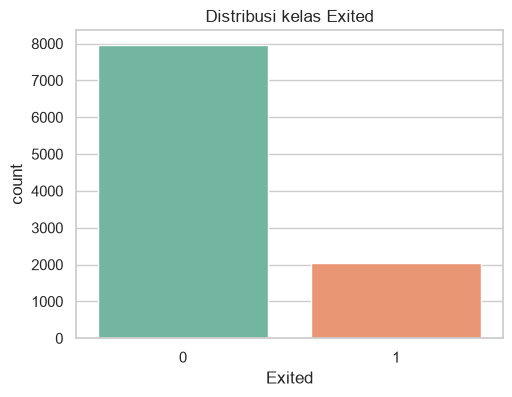

In [3]:
# Tampilkan distribusi kelas target (Exited) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.

print("Distribusi kelas Exited:")
print(df["Exited"].value_counts().to_string())
print(f"Rasio churn: {df['Exited'].mean():.3f}")

plt.figure(figsize=(5.5, 4))
sns.countplot(data=df, x="Exited", hue="Exited", palette="Set2", legend=False)
plt.title("Distribusi kelas Exited")
plt.show()


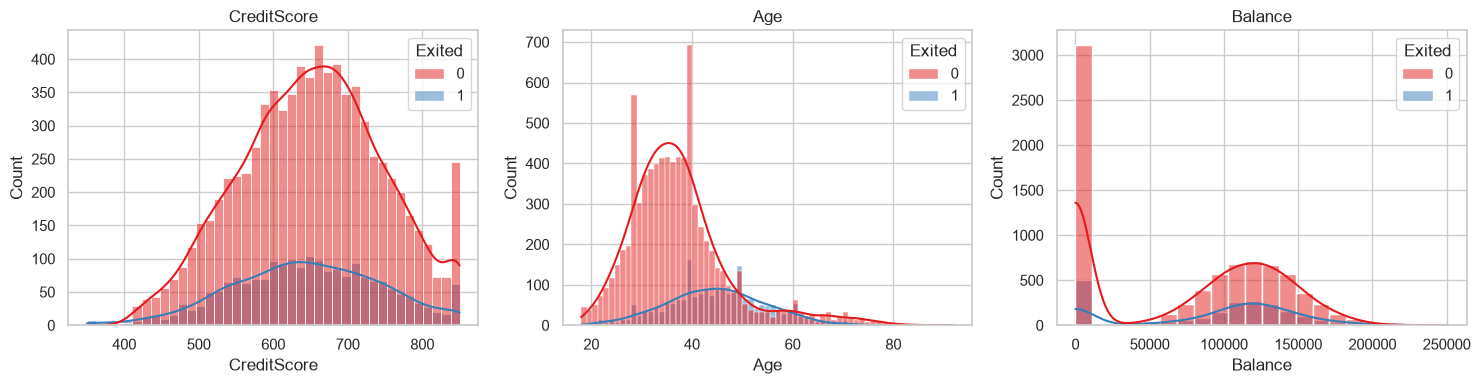

In [4]:
# Tampilkan distribusi fitur numerik (misalnya Age, CreditScore, Balance) menggunakan histogram atau KDE plot, dibedakan berdasarkan kelas Exited.

num_cols = ["CreditScore", "Age", "Balance"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, num_cols):
    sns.histplot(data=df, x=c, hue="Exited", kde=True, ax=ax, palette="Set1")
    ax.set_title(c)
plt.tight_layout()
plt.show()


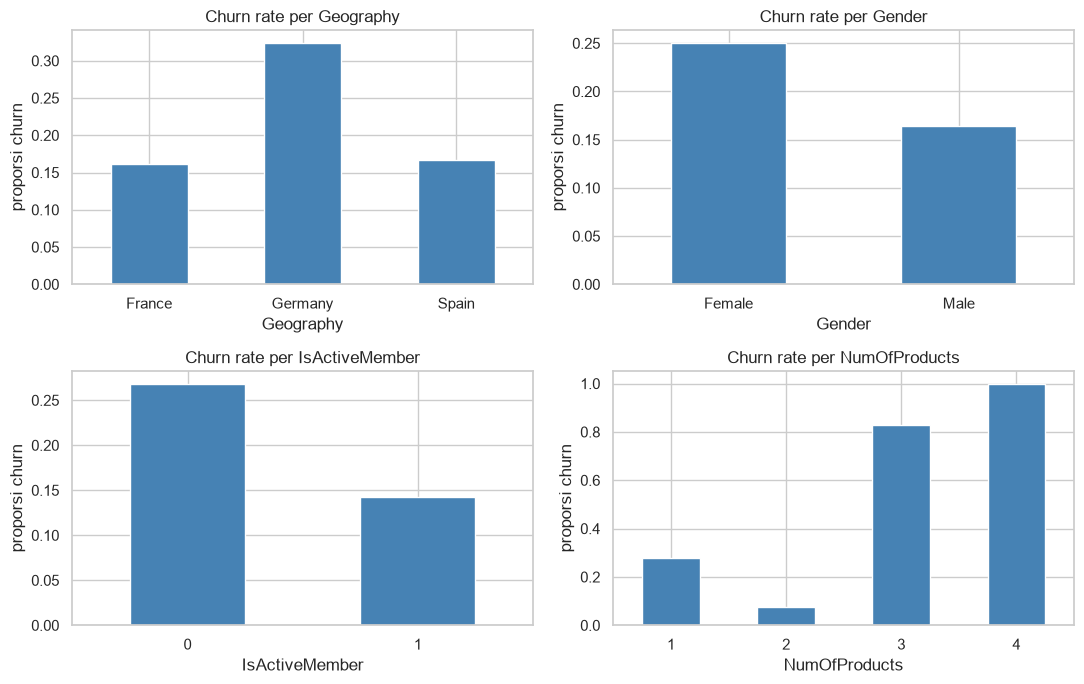

In [5]:
# Tampilkan proporsi churn untuk setiap kategori pada fitur kategorikal (Geography, Gender, IsActiveMember, NumOfProducts).

cat_cols = ["Geography", "Gender", "IsActiveMember", "NumOfProducts"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, c in zip(axes.flat, cat_cols):
    df.groupby(c)["Exited"].mean().plot(kind="bar", ax=ax, color="steelblue", rot=0)
    ax.set_ylabel("proporsi churn")
    ax.set_title(f"Churn rate per {c}")
plt.tight_layout()
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

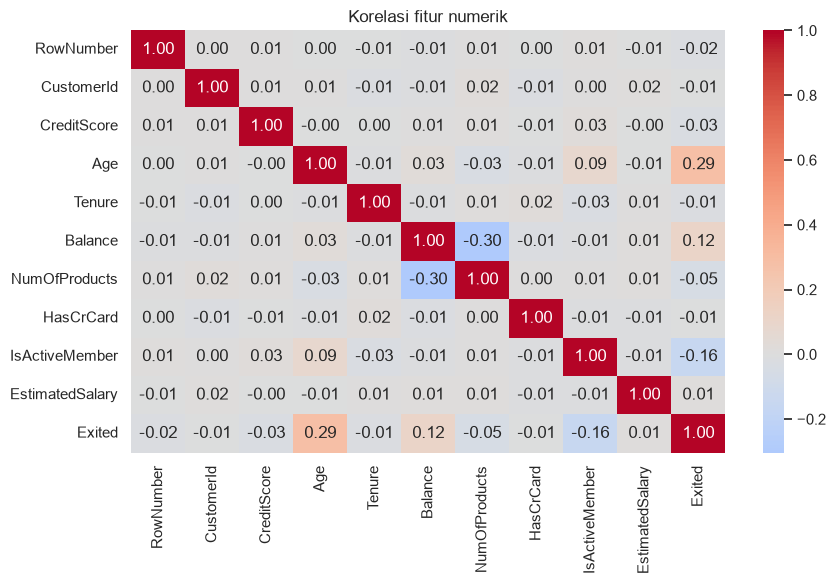

In [6]:
# Korelasi antar fitur numerik dengan target
plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Korelasi fitur numerik")
plt.tight_layout()
plt.show()


# 2. Preprocessing

ANN hanya menerima input numerik dan sangat sensitif terhadap skala fitur. Perhatikan jenis setiap kolom sebelum memilih preprocessing:

| Jenis kolom | Contoh | Preprocessing |
|---|---|---|
| Identitas (tidak informatif) | RowNumber, CustomerId, Surname | Drop |
| Kategorikal nominal | Geography | OneHotEncoder |
| Kategorikal biner | Gender | Encode menjadi 0/1 |
| Numerik | CreditScore, Age, Balance, dll. | StandardScaler |

In [7]:
# Drop kolom yang tidak relevan untuk prediksi.
# Jelaskan secara singkat (dalam komentar) alasan kolom tersebut di-drop.

# RowNumber, CustomerId, Surname: identitas unik baris, tidak informatif untuk prediksi
df_clean = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
print("Kolom tersisa:", df_clean.columns.tolist())
print(df_clean.head().to_string(index=False))


Kolom tersisa: ['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']
 CreditScore Geography Gender  Age  Tenure   Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Exited
         619    France Female   42       2      0.00              1          1               1        101348.88       1
         608     Spain Female   41       1  83807.86              1          0               1        112542.58       0
         502    France Female   42       8 159660.80              3          1               0        113931.57       1
         699    France Female   39       1      0.00              2          0               0         93826.63       0
         850     Spain Female   43       2 125510.82              1          1               1         79084.10       0


In [8]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set, validation set, dan test set (misalnya 70:15:15).
# Gunakan stratify=y agar distribusi kelas tetap proporsional di setiap set.
# Validation set digunakan untuk memantau training (learning curve), test set hanya digunakan untuk evaluasi akhir.

X = df_clean.drop(columns="Exited")
y = df_clean["Exited"]

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.3, stratify=y,
                                                  random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5,
                                                stratify=y_tmp, random_state=42)
print("train:", len(X_train), "| val:", len(X_val), "| test:", len(X_test))
print("Rasio churn train/val/test:",
      round(y_train.mean(), 3), round(y_val.mean(), 3), round(y_test.mean(), 3))


train: 7000 | val: 1500 | test: 1500
Rasio churn train/val/test: 0.204 0.204 0.203


In [9]:
# Lakukan encoding pada fitur kategorikal dan scaling pada fitur numerik.
# Fit encoder dan scaler hanya pada train set, kemudian transform pada train, validation, dan test set.
# Disarankan menggunakan ColumnTransformer agar rapi.

num_features = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                "HasCrCard", "IsActiveMember", "EstimatedSalary"]
cat_features = ["Geography", "Gender"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features),
])
X_train_p = preprocess.fit_transform(X_train)   # fit hanya pada train
X_val_p = preprocess.transform(X_val)
X_test_p = preprocess.transform(X_test)

print("Bentuk fitur train:", X_train_p.shape)
print("Nama fitur setelah preprocessing:", list(preprocess.get_feature_names_out()))


Bentuk fitur train: (7000, 13)
Nama fitur setelah preprocessing: ['num__CreditScore', 'num__Age', 'num__Tenure', 'num__Balance', 'num__NumOfProducts', 'num__HasCrCard', 'num__IsActiveMember', 'num__EstimatedSalary', 'cat__Geography_France', 'cat__Geography_Germany', 'cat__Geography_Spain', 'cat__Gender_Female', 'cat__Gender_Male']


In [10]:
# Ubah X dan y untuk train, validation, dan test menjadi tensor bertipe float32.
# Bentuk y diubah menjadi (N, 1) agar sesuai dengan output model, contoh: torch.tensor(y, dtype=torch.float32).view(-1, 1)
# Buat DataLoader untuk train set (shuffle=True) menggunakan TensorDataset.

BATCH = 64

def to_tensor(X, y):
    return TensorDataset(torch.tensor(X, dtype=torch.float32),
                         torch.tensor(y.values, dtype=torch.float32).view(-1, 1))

train_dl = DataLoader(to_tensor(X_train_p, y_train), batch_size=BATCH, shuffle=True)
val_dl = DataLoader(to_tensor(X_val_p, y_val), batch_size=BATCH)
test_dl = DataLoader(to_tensor(X_test_p, y_test), batch_size=BATCH)

print("Jumlah batch train/val/test:", len(train_dl), len(val_dl), len(test_dl))


Jumlah batch train/val/test: 110 24 24


# 3. Eksperimen Model

## 3.1 Baseline: Logistic Regression

Sebelum membangun ANN, buat model sederhana sebagai pembanding. Model yang lebih kompleks hanya layak digunakan jika performanya lebih baik dari baseline.

In [11]:
# Inisialisasi dan latih model Logistic Regression (sklearn) menggunakan train set.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_p, y_train)

y_pred_lr = lr_model.predict(X_test_p)
y_prob_lr = lr_model.predict_proba(X_test_p)[:, 1]
print("Logistic Regression - test accuracy:",
      round(accuracy_score(y_test, y_pred_lr), 4))


Logistic Regression - test accuracy: 0.8153


## 3.2 ANN Sederhana

Bangun ANN dengan **1 hidden layer** dan **1 neuron output**. Di PyTorch, output layer cukup berupa `nn.Linear` tanpa Sigmoid, lalu gunakan **`nn.BCEWithLogitsLoss`** sebagai loss function. Loss ini sudah menggabungkan Sigmoid dan Binary Cross-Entropy sehingga lebih stabil secara numerik.

Contoh arsitektur: `Input → Linear(16) → ReLU → Linear(1)`

In [12]:
# Definisikan arsitektur ANN sederhana sebagai class turunan nn.Module (gunakan nn.Sequential, nn.Linear, dan nn.ReLU).
# Tampilkan arsitektur model dengan print(model) dan hitung jumlah parameternya: sum(p.numel() for p in model.parameters()).

class SimpleANN(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 16), nn.ReLU(), nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.net(x)

model_simple = SimpleANN(X_train_p.shape[1])
print(model_simple)
print("Jumlah parameter:", sum(p.numel() for p in model_simple.parameters()))


SimpleANN(
  (net): Sequential(
    (0): Linear(in_features=13, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)
Jumlah parameter: 241


In [13]:
# Tentukan loss function (nn.BCEWithLogitsLoss), optimizer (misalnya torch.optim.Adam), learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Untuk setiap batch: forward -> hitung loss -> optimizer.zero_grad() -> loss.backward() -> optimizer.step().
# Di akhir setiap epoch, hitung loss dan accuracy pada train set dan validation set (gunakan model.eval() dan torch.no_grad()),
# lalu simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.3 dan 3.4.

EPOCHS, LR = 50, 1e-3

def train_model(model, train_dl, val_dl, epochs=EPOCHS, lr=LR, criterion=None):
    model = model.to(DEVICE)
    criterion = criterion if criterion is not None else nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for ep in range(epochs):
        model.train()
        running = correct = tot = 0
        for xb, yb in train_dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = model(xb)
            loss = criterion(logits, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
            correct += ((torch.sigmoid(logits) >= 0.5).float() == yb).sum().item()
            tot += len(xb)
        history["train_loss"].append(running / tot)
        history["train_acc"].append(correct / tot)

        model.eval()
        running = correct = tot = 0
        with torch.no_grad():
            for xb, yb in val_dl:
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                logits = model(xb)
                running += criterion(logits, yb).item() * len(xb)
                correct += ((torch.sigmoid(logits) >= 0.5).float() == yb).sum().item()
                tot += len(xb)
        history["val_loss"].append(running / tot)
        history["val_acc"].append(correct / tot)

        if ep == 0 or (ep + 1) % 10 == 0:
            print(f"epoch {ep + 1:3d}/{epochs} | train loss {history['train_loss'][-1]:.4f} "
                  f"acc {history['train_acc'][-1]:.4f} | val loss {history['val_loss'][-1]:.4f} "
                  f"acc {history['val_acc'][-1]:.4f}")
    return history

history_simple = train_model(model_simple, train_dl, val_dl, epochs=EPOCHS, lr=LR)


epoch   1/50 | train loss 0.6101 acc 0.7160 | val loss 0.5208 acc 0.7960


epoch  10/50 | train loss 0.3610 acc 0.8513 | val loss 0.3445 acc 0.8580


epoch  20/50 | train loss 0.3440 acc 0.8587 | val loss 0.3280 acc 0.8633


epoch  30/50 | train loss 0.3403 acc 0.8609 | val loss 0.3250 acc 0.8633


epoch  40/50 | train loss 0.3378 acc 0.8594 | val loss 0.3235 acc 0.8613


epoch  50/50 | train loss 0.3365 acc 0.8604 | val loss 0.3213 acc 0.8673


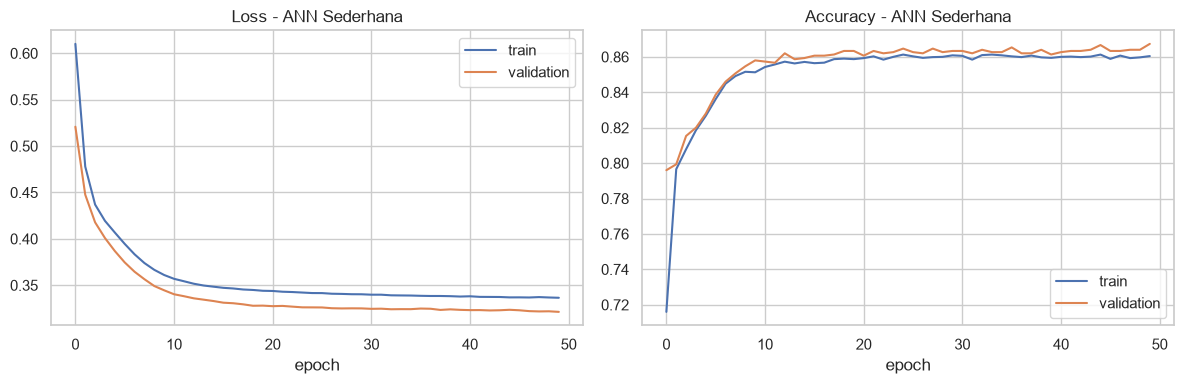

In [14]:
# Tampilkan learning curve (loss dan accuracy) train vs validation dalam bentuk line plot menggunakan dictionary history.

def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="train")
    axes[0].plot(history["val_loss"], label="validation")
    axes[0].set_title(f"Loss - {title}")
    axes[0].set_xlabel("epoch")
    axes[0].legend()
    axes[1].plot(history["train_acc"], label="train")
    axes[1].plot(history["val_acc"], label="validation")
    axes[1].set_title(f"Accuracy - {title}")
    axes[1].set_xlabel("epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(history_simple, "ANN Sederhana")


In [15]:
# Lakukan prediksi pada test set. Gunakan model.eval() dan torch.no_grad().
# Output model berupa logit, ubah menjadi probabilitas dengan torch.sigmoid(), lalu menjadi label dengan threshold 0.5.
# Simpan probabilitas dan label dalam bentuk numpy array untuk keperluan evaluasi.

def predict(model, dl):
    model.eval()
    probs = []
    with torch.no_grad():
        for xb, _ in dl:
            probs.append(torch.sigmoid(model(xb.to(DEVICE))).cpu().numpy().ravel())
    probs = np.concatenate(probs)
    return probs, (probs >= 0.5).astype(int)

y_prob_simple, y_pred_simple = predict(model_simple, test_dl)
print("ANN Sederhana - test accuracy:",
      round(accuracy_score(y_test, y_pred_simple), 4))


ANN Sederhana - test accuracy: 0.8673


## 3.3 ANN Lebih Dalam dengan Dropout

Bangun ANN dengan **2–3 hidden layer** dan tambahkan **Dropout** di antara hidden layer untuk mengurangi overfitting.

In [16]:
# Definisikan arsitektur ANN yang lebih dalam, tambahkan nn.Dropout(p) di antara hidden layer.
# Ingat: Dropout hanya aktif saat model.train() dan otomatis nonaktif saat model.eval().
# Tampilkan arsitektur model beserta jumlah parameternya.

class DeepANN(nn.Module):
    def __init__(self, n_in, p=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_in, 64), nn.ReLU(), nn.Dropout(p),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(p),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.net(x)

model_deep = DeepANN(X_train_p.shape[1])
print(model_deep)
print("Jumlah parameter:", sum(p.numel() for p in model_deep.parameters()))


DeepANN(
  (net): Sequential(
    (0): Linear(in_features=13, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)
Jumlah parameter: 3009


epoch   1/50 | train loss 0.5012 acc 0.7961 | val loss 0.4309 acc 0.7987


epoch  10/50 | train loss 0.3651 acc 0.8479 | val loss 0.3352 acc 0.8620


epoch  20/50 | train loss 0.3547 acc 0.8553 | val loss 0.3270 acc 0.8627


epoch  30/50 | train loss 0.3488 acc 0.8586 | val loss 0.3216 acc 0.8667


epoch  40/50 | train loss 0.3425 acc 0.8641 | val loss 0.3160 acc 0.8713


epoch  50/50 | train loss 0.3371 acc 0.8640 | val loss 0.3178 acc 0.8687


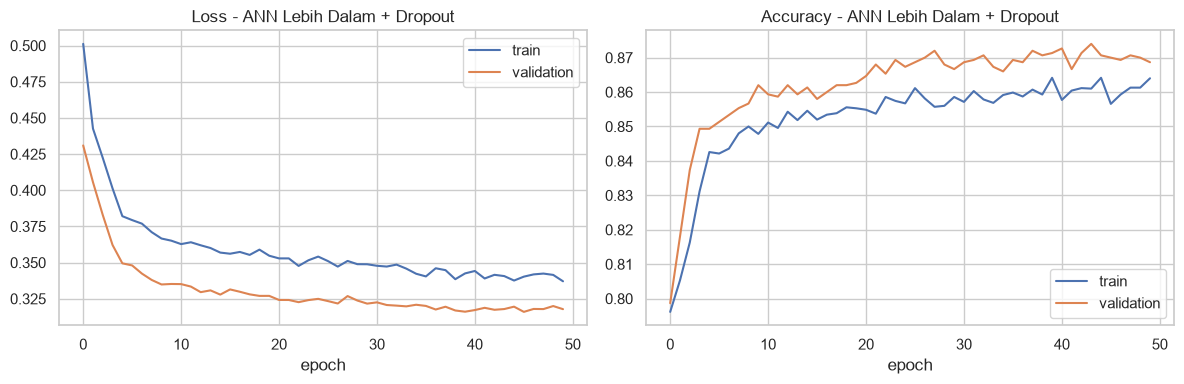

In [17]:
# Latih model dengan cara yang sama seperti 3.2, lalu tampilkan learning curve train vs validation.
# Bandingkan bentuk learning curve-nya dengan model 3.2. Apakah ada tanda overfitting?

history_deep = train_model(model_deep, train_dl, val_dl, epochs=EPOCHS, lr=LR)
plot_history(history_deep, "ANN Lebih Dalam + Dropout")


In [18]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.

y_prob_deep, y_pred_deep = predict(model_deep, test_dl)
print("ANN Deep + Dropout - test accuracy:",
      round(accuracy_score(y_test, y_pred_deep), 4))


ANN Deep + Dropout - test accuracy: 0.8693


## 3.4 Penanganan Data Imbalanced

Pada data imbalanced, model cenderung lebih sering memprediksi kelas mayoritas sehingga recall kelas churn rendah. Salah satu cara mengatasinya adalah dengan memberi bobot lebih besar pada kelas minoritas di loss function.

In [19]:
# Gunakan arsitektur terbaik dari 3.2 atau 3.3 (buat ulang modelnya agar bobot mulai dari awal), lalu latih dengan class weight.
# Hitung pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set.
# Masukkan ke loss function: nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight])).

# Pilih arsitektur terbaik (3.2 atau 3.3) berdasarkan accuracy terakhir pada validation set
best_arch = "deep" if history_deep["val_acc"][-1] >= history_simple["val_acc"][-1] else "simple"
print("Arsitektur terbaik:", best_arch)

# pos_weight = jumlah kelas 0 / jumlah kelas 1 pada train set
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("pos_weight:", round(pos_weight, 3))
criterion_w = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor([pos_weight], dtype=torch.float32, device=DEVICE))

model_w = DeepANN(X_train_p.shape[1]) if best_arch == "deep" else SimpleANN(X_train_p.shape[1])
history_w = train_model(model_w, train_dl, val_dl, epochs=EPOCHS, lr=LR, criterion=criterion_w)


Arsitektur terbaik: deep
pos_weight: 3.909


epoch   1/50 | train loss 1.0392 acc 0.5536 | val loss 0.9140 acc 0.7067


epoch  10/50 | train loss 0.7824 acc 0.7711 | val loss 0.7128 acc 0.7907


epoch  20/50 | train loss 0.7512 acc 0.7899 | val loss 0.6941 acc 0.8133


epoch  30/50 | train loss 0.7420 acc 0.7919 | val loss 0.6931 acc 0.7993


epoch  40/50 | train loss 0.7367 acc 0.7896 | val loss 0.6929 acc 0.7993


epoch  50/50 | train loss 0.7279 acc 0.7960 | val loss 0.6849 acc 0.8060


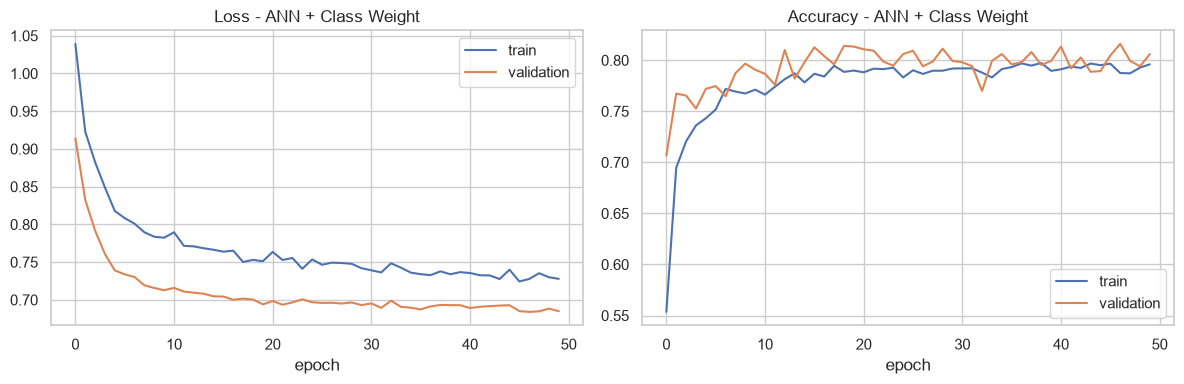

ANN + Class Weight - test accuracy: 0.8013


In [20]:
# Tampilkan learning curve train vs validation.
# Lakukan prediksi pada test set, simpan hasil prediksi label dan probabilitas kelas 1.

plot_history(history_w, "ANN + Class Weight")
y_prob_w, y_pred_w = predict(model_w, test_dl)
print("ANN + Class Weight - test accuracy:",
      round(accuracy_score(y_test, y_pred_w), 4))


# 4. Evaluasi Model

In [21]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

models = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "ANN Sederhana": (y_pred_simple, y_prob_simple),
    "ANN Deep + Dropout": (y_pred_deep, y_prob_deep),
    "ANN + Class Weight": (y_pred_w, y_prob_w),
}

rows = []
for name, (pred, prob) in models.items():
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1-Score": f1_score(y_test, pred),
                 "AUC": roc_auc_score(y_test, prob)})
metrics_df = pd.DataFrame(rows).round(4)
print(metrics_df.to_string(index=False))


              Model  Accuracy  Precision  Recall  F1-Score    AUC
Logistic Regression    0.8153     0.6458  0.2033    0.3092 0.7912
      ANN Sederhana    0.8673     0.7849  0.4787    0.5947 0.8697
 ANN Deep + Dropout    0.8693     0.8428  0.4393    0.5776 0.8668
 ANN + Class Weight    0.8013     0.5076  0.7639    0.6099 0.8708


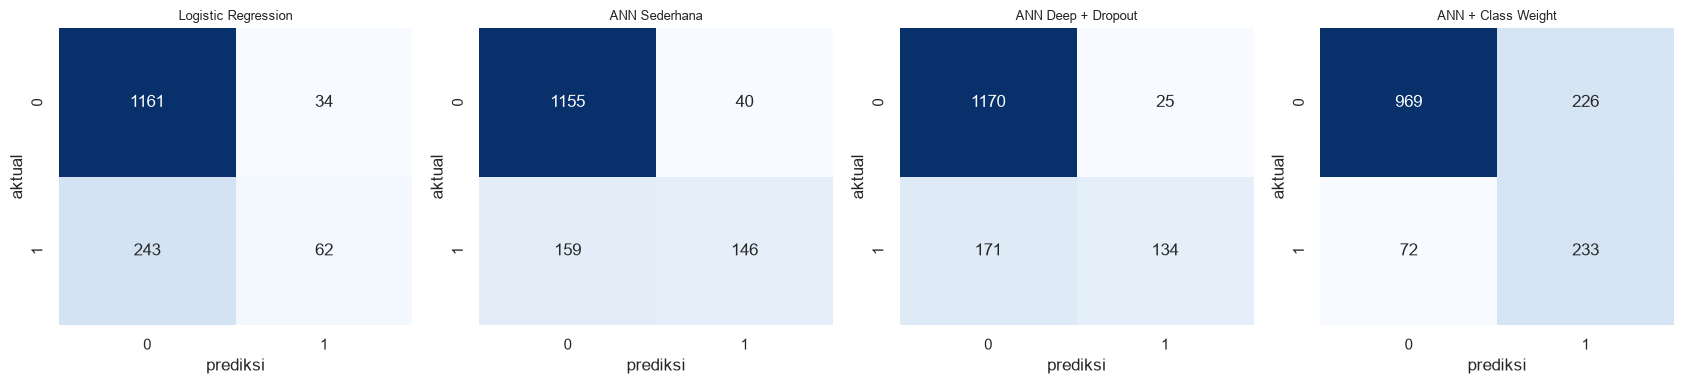

In [22]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun dalam satu baris subplot.

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (name, (pred, _)) in zip(axes, models.items()):
    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d", cmap="Blues",
                ax=ax, cbar=False)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("prediksi")
    ax.set_ylabel("aktual")
plt.tight_layout()
plt.show()


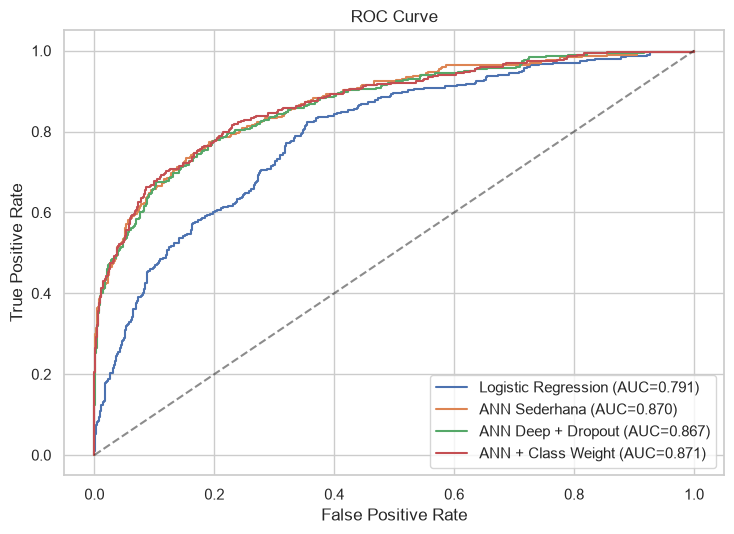

In [23]:
# Tampilkan ROC Curve seluruh model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(7.5, 5.5))
for name, (_, prob) in models.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()


# 5. Analisis

Berdasarkan hasil eksperimen, dataset Customer Churn memiliki distribusi kelas yang tidak seimbang, dengan 7.963 nasabah tidak churn dan 2.037 nasabah churn. Kondisi ini menyebabkan model cenderung lebih mudah mengenali kelas mayoritas dibandingkan kelas churn. Pada tahap preprocessing, fitur kategorikal diubah menggunakan OneHotEncoder dan fitur numerik dinormalisasi menggunakan StandardScaler. Dataset kemudian dibagi menjadi training, validation, dan testing dengan proporsi 70:15:15 menggunakan stratified splitting agar distribusi kelas tetap terjaga.

Hasil evaluasi menunjukkan bahwa Logistic Regression memperoleh accuracy sebesar 81,53%, tetapi recall kelas churn hanya mencapai 0,2033 dengan F1-Score sebesar 0,3092. Hal ini menunjukkan bahwa model baseline masih kesulitan mengenali sebagian besar nasabah yang benar-benar churn. Setelah menggunakan ANN sederhana dengan 241 parameter, accuracy meningkat menjadi 86,73%, recall menjadi 0,4787, dan F1-Score mencapai 0,5947. Peningkatan tersebut menunjukkan bahwa ANN mampu mempelajari hubungan non-linear antar fitur yang tidak dapat ditangkap secara langsung oleh Logistic Regression.

Penggunaan ANN Deep dengan Dropout menghasilkan accuracy tertinggi sebesar 86,93% dan precision sebesar 0,8428. Namun, recall menurun menjadi 0,4393 dan F1-Score menjadi 0,5776. Meskipun memiliki 3.009 parameter dan arsitektur yang lebih kompleks, model ini tidak memberikan peningkatan pada seluruh metrik. Berdasarkan learning curve, kedua model ANN mengalami penurunan training loss dan validation loss secara bertahap. Pada ANN Deep, penggunaan Dropout membantu proses regularisasi, sedangkan validation loss yang masih berfluktuasi pada akhir training menunjukkan bahwa penambahan kompleksitas belum tentu menghasilkan generalisasi yang lebih baik.

Pada eksperimen penanganan data imbalanced, penggunaan Class Weight menghasilkan recall tertinggi sebesar 0,7639 dan F1-Score sebesar 0,6099. Namun, accuracy menurun menjadi 80,13% dan precision menjadi 0,5076. Berdasarkan Confusion Matrix, peningkatan recall menunjukkan bahwa model lebih banyak mengenali nasabah churn, tetapi juga menghasilkan lebih banyak false positive. Hal ini terjadi karena pemberian bobot lebih besar pada kelas minoritas membuat model lebih memperhatikan kesalahan prediksi pada kelas churn.

Berdasarkan ROC-AUC, ANN dengan Class Weight memperoleh nilai tertinggi sebesar 0,8708, diikuti ANN sederhana sebesar 0,8697 dan ANN Deep sebesar 0,8668. Perbedaan nilai yang relatif kecil menunjukkan bahwa ketiga model ANN memiliki kemampuan diskriminasi kelas yang cukup berdekatan. Secara keseluruhan, ANN Deep lebih unggul dari sisi accuracy dan precision, sedangkan ANN dengan Class Weight lebih sesuai apabila tujuan prediksi adalah mendeteksi sebanyak mungkin nasabah yang berpotensi churn.

# 6. Kesimpulan dan Saran

Kesimpulan

Berdasarkan hasil eksperimen, penggunaan Artificial Neural Network (ANN) mampu memberikan performa yang lebih baik dibandingkan Logistic Regression dalam memprediksi customer churn. Model ANN Deep dengan Dropout memperoleh accuracy tertinggi sebesar 86,93%, sedangkan ANN sederhana memperoleh accuracy sebesar 86,73%. Namun, ANN sederhana memiliki F1-Score yang lebih tinggi, yaitu 0,5947 dibandingkan 0,5776 pada ANN Deep.

Penerapan Class Weight meningkatkan recall kelas churn menjadi 0,7639 dengan F1-Score sebesar 0,6099, meskipun accuracy menurun menjadi 80,13%. Hal ini menunjukkan bahwa penanganan data imbalanced membantu model mengenali lebih banyak nasabah yang berpotensi churn, tetapi juga meningkatkan kemungkinan kesalahan prediksi pada nasabah yang tidak churn.

Saran

Untuk eksperimen selanjutnya, dapat dilakukan hyperparameter tuning pada jumlah hidden layer, jumlah neuron, learning rate, dan dropout rate untuk memperoleh performa yang lebih optimal. Selain itu, penggunaan threshold tuning dan metode penanganan data imbalanced lainnya seperti SMOTE dapat dicoba untuk meningkatkan recall tanpa menurunkan precision secara berlebihan. Evaluasi model juga sebaiknya lebih berfokus pada F1-Score dan recall, terutama apabila tujuan utamanya adalah mendeteksi nasabah yang berpotensi churn.